# Milestone 4 - Hybrid retrieval & Reciprocal Rank Fusion

Sparse (lexical, BM25-like) and dense (semantic) searches run against Qdrant and their ranked lists are merged with **Reciprocal Rank Fusion**: `score(d) = sum_i 1/(k + rank_i(d))`, k = 60 (Cormack et al., 2009). Evaluated on the 200-pair held-out test set with page-level relevance labels.

In [1]:
import os, sys, json, time, warnings, pathlib
warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
from rag import config

In [2]:
from rag import metrics, store
from rag.corpus import load_jsonl
from rag.retrieval import HybridRetriever, rrf_fuse
store.ensure_qdrant()
r = HybridRetriever()
test = load_jsonl(config.EVAL_DIR / "test_qa.jsonl")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

### Anatomy of one query

In [3]:
q = "What is the most liquid the HX-360 can move per minute?"
dense_q, sparse_q = r.encode_query(q)
lists = {"dense": store.search_dense(r.qc, dense_q, 10), "sparse": store.search_sparse(r.qc, sparse_q, 10)}
fused = rrf_fuse(lists)
pd.DataFrame([{k: f.get(k) for k in ("chunk_id", "dense_rank", "sparse_rank", "rrf_score")} for f in fused[:8]])

,chunk_id,dense_rank,sparse_rank,rrf_score
0,HX_Pump_Selection_Guide.md::8::0,1.0,1,0.032787
1,HX_Pump_Series_Technical_Specification.docx::9::1,2.0,3,0.032002
2,HX_Pump_Series_Technical_Specification.docx::9::0,4.0,2,0.031754
3,HX_Pump_Selection_Guide.md::7::0,3.0,9,0.030366
4,HX_Pump_Selection_Guide.md::12::0,5.0,8,0.030090
5,HX_Pump_Selection_Guide.md::6::0,8.0,6,0.029857
6,HX_Pump_Selection_Guide.md::5::0,9.0,10,0.028778
7,HX_Pump_Selection_Guide.md::1::0,NaN,4,0.015625


### Dense vs sparse vs hybrid on the test set (top-5)

In [4]:
rows = {"dense only": [], "sparse only": [], "hybrid (RRF)": []}
lat = []
for row in test:
    rows["dense only"].append(metrics.retrieval_scores(r.retrieve_single(row["question"], "dense", 5), row))
    rows["sparse only"].append(metrics.retrieval_scores(r.retrieve_single(row["question"], "sparse", 5), row))
    t = time.perf_counter(); cands = r.retrieve(row["question"], 30); lat.append(time.perf_counter() - t)
    rows["hybrid (RRF)"].append(metrics.retrieval_scores(cands[:5], row))
    row["_recall30"] = metrics.context_recall(metrics.relevance(cands, row["doc"], row["page"]))
res = pd.DataFrame({k: metrics.mean_scores(v) for k, v in rows.items()}).T.round(3)
res

,context_precision,context_recall,mrr,hit@1,answer_chunk@1
dense only,0.793,0.950,0.803,0.685,0.71
sparse only,0.901,0.995,0.920,0.860,0.85
hybrid (RRF),0.852,0.995,0.859,0.750,0.76


hybrid candidate recall@30 (what the reranker gets to see): 1.000
hybrid retrieval latency: mean 17 ms, max 23 ms


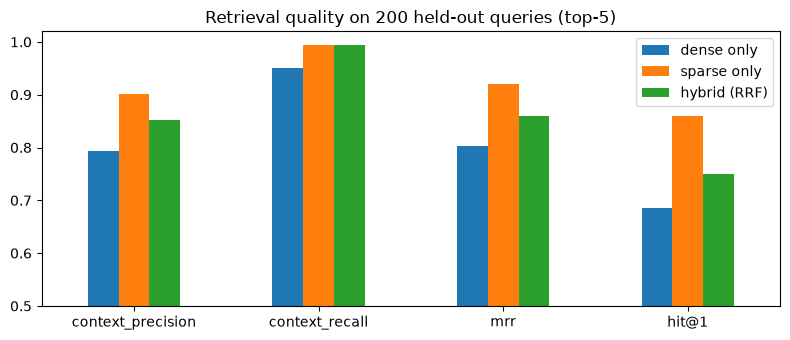

In [5]:
print(f"hybrid candidate recall@30 (what the reranker gets to see): {sum(r_['_recall30'] for r_ in test)/len(test):.3f}")
print(f"hybrid retrieval latency: mean {1000*sum(lat)/len(lat):.0f} ms, max {1000*max(lat):.0f} ms")
ax = res[["context_precision", "context_recall", "mrr", "hit@1"]].T.plot.bar(figsize=(8, 3.5), rot=0)
ax.set_ylim(0.5, 1.02); ax.set_title("Retrieval quality on 200 held-out queries (top-5)"); plt.tight_layout()
plt.savefig(config.ARTIFACT_DIR / "retrieval_comparison.png", dpi=120); plt.show()

Dense search alone misses exact identifiers (asset IDs, work-order numbers); sparse search alone misses paraphrases. Fusion keeps recall@30 essentially perfect, but top-1 precision is still limited - which is what the cross-encoder in Milestone 5 fixes.